# Ejercicio Final: Laboratorio de IA Ética

**Nombre:** Jhonnatan Peñate

**Bootcamp Python – PY4**
**Módulo:** Machine Learning Avanzado y Feature Engineering

---

Este es el ejercicio final del módulo. Vas a repetir, de forma independiente, el mismo proceso que practicamos en las 3 sesiones anteriores: entrenar un modelo, explicarlo con SHAP y LIME, y evaluar si se apoya en variables sesgadas o inapropiadas.

La diferencia es que hoy vamos a trabajar con un dataset nuevo, que no vimos en clase: **COMPAS**, un sistema real usado en Estados Unidos para predecir el riesgo de que una persona reincida (vuelva a cometer un delito) dentro de los siguientes dos años. Este dataset fue el centro de una investigación periodística muy conocida (ProPublica, 2016), que encontró que el sistema clasificaba a personas afroamericanas como de "alto riesgo" con mucha más frecuencia que a personas blancas, incluso cuando la tasa real de reincidencia era similar entre ambos grupos.

El ejercicio está dividido en las mismas 4 fases que ya conoces. Las celdas de código están dejadas en blanco, con comentarios que te guían paso a paso. Las celdas de texto marcadas como "Tu turno" son las que tienes que completar con tu propio análisis.

## Fase 1: Entrenamiento del Modelo Base

Como en la Sesión 1, empezamos preparando el entorno y cargando el dataset.

### Preparar el entorno

Instala y luego importa las librerías que vas a necesitar durante todo el ejercicio.

In [1]:
!pip install xgboost shap lime scikit-learn joblib -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 4.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [2]:
import pandas as pd
import numpy as np
import re

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

import xgboost as xgb
import shap
from lime.lime_tabular import LimeTabularExplainer

import matplotlib.pyplot as plt

### Cargar el dataset

Vamos a cargar el dataset COMPAS directamente desde el repositorio público de ProPublica en GitHub, seleccionando solo las columnas relevantes para este ejercicio, y aplicando el filtro estándar que usa la propia documentación de ProPublica (elimina casos con fechas de arresto inconsistentes y cargos sin clasificar). Esta parte te la dejamos resuelta, para que puedas enfocarte en el resto del análisis.

In [3]:
url = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"

columnas = [
    "sex", "age", "age_cat", "race",
    "juv_fel_count", "juv_misd_count", "juv_other_count", "priors_count",
    "c_charge_degree", "days_b_screening_arrest", "is_recid", "two_year_recid"
]

df = pd.read_csv(url, usecols=columnas)

# Filtro estandar de ProPublica: descarta registros con fechas de arresto inconsistentes,
# casos sin informacion de reincidencia, y cargos sin clasificar (grado "O")
df = df[(df["days_b_screening_arrest"] <= 30) & (df["days_b_screening_arrest"] >= -30)]
df = df[df["is_recid"] != -1]
df = df[df["c_charge_degree"] != "O"]
df = df.drop(columns=["days_b_screening_arrest", "is_recid"])

print("Filas despues del filtro:", df.shape[0])
df.head()

Filas despues del filtro: 6172


,sex,age,age_cat,race,juv_fel_count,juv_misd_count,juv_other_count,priors_count,c_charge_degree,two_year_recid
0,Male,69,Greater than 45,Other,0,0,0,0,F,0
1,Male,34,25 - 45,African-American,0,0,0,0,F,1
2,Male,24,Less than 25,African-American,0,0,1,4,F,1
5,Male,44,25 - 45,Other,0,0,0,0,M,0
6,Male,41,25 - 45,Caucasian,0,0,0,14,F,1


### Diccionario de variables

| Columna | Descripción |
|---|---|
| `sex` | Sexo de la persona **(variable sensible)** |
| `age` | Edad de la persona |
| `age_cat` | Categoría de edad (menor a 25, 25-45, mayor a 45) |
| `race` | Raza de la persona **(variable sensible)** |
| `juv_fel_count` | Cantidad de delitos graves cometidos como menor de edad |
| `juv_misd_count` | Cantidad de delitos menores cometidos como menor de edad |
| `juv_other_count` | Otros registros como menor de edad |
| `priors_count` | Cantidad de antecedentes penales previos |
| `c_charge_degree` | Gravedad del cargo actual (`F` = felonía, `M` = delito menor) |
| `two_year_recid` | Variable objetivo: `1` = reincidió dentro de 2 años, `0` = no reincidió |

Ten en cuenta `race` y `sex` durante todo el ejercicio: vamos a volver a ellas en la Fase 4.

### Tu turno: preprocesamiento

Prepara los datos para entrenar el modelo:

1. Define `X` (todas las columnas excepto la variable objetivo) e `y` (`two_year_recid`).
2. Codifica las variables categóricas con one-hot encoding.
3. Limpia los nombres de columnas si es necesario (recuerda la función `limpiar_nombre_columna` que usamos en sesiones anteriores).

In [4]:
## funcion para limpiar los nombres de columna

def limpiar_nombre_columna(col):
    col = re.sub(r"[\[\]<>=,/:&()]", "", col)
    col = re.sub(r"[\s\.\-]+", "_", col.strip())
    col = re.sub(r"_+", "_", col).strip("_")
    return col.lower()

In [5]:
target = "two_year_recid"

X = df.drop(columns=[target])
y = df[target]

X_enc = pd.get_dummies(X, drop_first=True)

X_enc.columns = [limpiar_nombre_columna(c) for c in X_enc.columns]

print("Shape despues de codificar:", X_enc.shape)

Shape despues de codificar: (6172, 14)


### Tu turno: separar en entrenamiento y prueba

Haz el split de entrenamiento y prueba. Recuerda usar `stratify` para mantener la proporción de la variable objetivo en ambos conjuntos.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Proporcion de reincidencia en train:", round(y_train.mean(), 3))
print("Proporcion de reincidencia en test:", round(y_test.mean(), 3))

Train shape: (4937, 14)
Test shape: (1235, 14)
Proporcion de reincidencia en train: 0.455
Proporcion de reincidencia en test: 0.455


### Tu turno: entrenar el modelo

Entrena un modelo XGBoost sobre el conjunto de entrenamiento.

In [7]:
model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

### Tu turno: evaluar el modelo

Evalúa el modelo con Accuracy y F1-Score, y revisa el `classification_report`.

In [8]:
y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", round(acc, 4))
print("F1-Score:", round(f1, 4))
print()
print(classification_report(y_test, y_pred))

Accuracy: 0.702
F1-Score: 0.6522

              precision    recall  f1-score   support

           0       0.71      0.78      0.74       673
           1       0.70      0.61      0.65       562

    accuracy                           0.70      1235
   macro avg       0.70      0.69      0.70      1235
weighted avg       0.70      0.70      0.70      1235



## Fase 2: Análisis Global (SHAP)

Usa `shap.TreeExplainer` para calcular los valores SHAP sobre el conjunto de entrenamiento, y genera un Summary Plot (beeswarm).

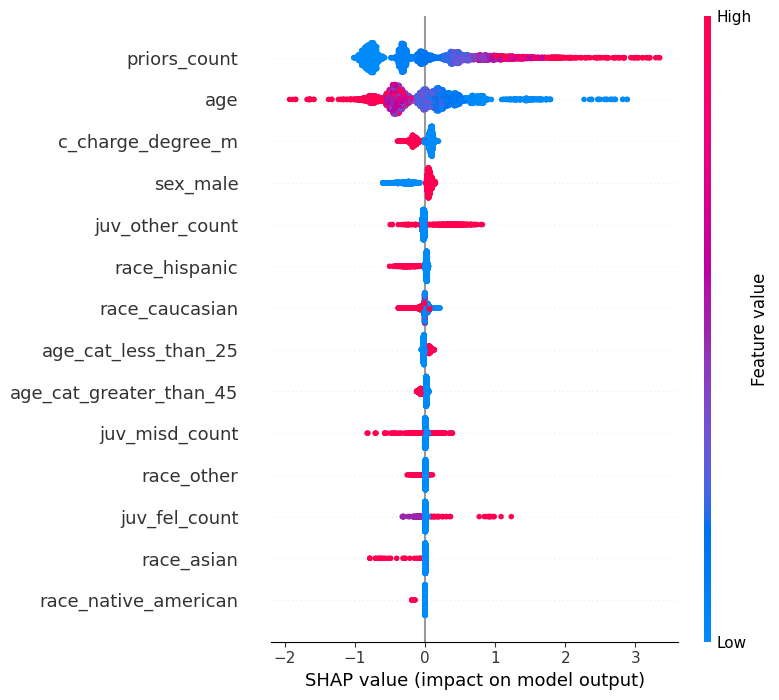

In [9]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_train)

shap.summary_plot(shap_values, X_train)

**Tu turno: narrativa requerida**

Con base en el beeswarm, identifica las 3 variables más influyentes del modelo y explica, para cada una, si empujan la predicción hacia "reincide" o hacia "no reincide", y por qué crees que tiene sentido (o no) que esa variable influya de esa manera.

*Tu turno: escribe aquí tu narrativa de las 3 variables más influyentes.*

Según el beeswarm de SHAP, las tres variables con mayor impacto promedio sobre la predicción son, en orden: **`priors_count`**, **`age`** y **`c_charge_degree_m`**.

1. **`priors_count` (cantidad de antecedentes penales previos)**: es, por amplio margen, la variable más influyente. Valores altos de antecedentes (puntos rojos en el beeswarm) se ubican del lado positivo del eje, empujando la predicción hacia "reincide", mientras que valores bajos (puntos azules) empujan hacia "no reincide". Tiene sentido que el modelo se apoye tanto en esta variable: el historial de conducta pasada es, estadísticamente, uno de los predictores más fuertes de conducta futura en criminología, y no depende de una característica demográfica sino del comportamiento observado de la persona.

2. **`age` (edad)**: la relación es inversa: personas más jóvenes (puntos azules, edad baja) tienden a tener SHAP positivo, es decir, el modelo las empuja hacia "reincide", mientras que personas mayores empujan hacia "no reincide". Esto también es consistente con la literatura criminológica (la reincidencia tiende a bajar con la edad), pero es una variable delicada porque penalizar a alguien por ser joven puede sentirse injusto a nivel individual, aunque sea un patrón real a nivel poblacional.

3. **`c_charge_degree_m` (cargo actual es delito menor, no felonía)**: cuando esta variable es verdadera (la persona fue arrestada por un delito menor), el SHAP tiende a ser negativo, es decir, empuja hacia "no reincide" en comparación con quienes enfrentan un cargo por felonía. Tiene sentido: la gravedad del cargo actual suele correlacionar con el nivel de riesgo que el sistema penal les asigna, y las felonías generalmente indican un patrón delictivo más serio.

## Fase 3: Análisis Local (SHAP y LIME)

Selecciona dos casos contrastantes del conjunto de prueba: uno donde el modelo prediga con alta confianza que la persona **va a reincidir**, y otro donde prediga con alta confianza que **no va a reincidir**. Elige estos casos entre las predicciones donde el modelo acertó, para que el análisis sea más claro.

In [10]:
df_test = X_test.copy()
df_test["proba_reincide"] = model.predict_proba(X_test)[:, 1]
df_test["prediccion"] = model.predict(X_test)
df_test["real"] = y_test.values

aciertos = df_test[df_test["prediccion"] == df_test["real"]]

idx_caso1 = aciertos["proba_reincide"].idxmax()  # alta probabilidad de reincidencia
idx_caso2 = aciertos["proba_reincide"].idxmin()  # baja probabilidad de reincidencia

print("Caso 1 (alta probabilidad de reincidencia) - indice:", idx_caso1,
      "- probabilidad:", round(aciertos.loc[idx_caso1, "proba_reincide"], 3))
print("Caso 2 (baja probabilidad de reincidencia) - indice:", idx_caso2,
      "- probabilidad:", round(aciertos.loc[idx_caso2, "proba_reincide"], 3))

Caso 1 (alta probabilidad de reincidencia) - indice: 1794 - probabilidad: 0.975
Caso 2 (baja probabilidad de reincidencia) - indice: 2849 - probabilidad: 0.076


### SHAP Waterfall: Caso 1

Genera el waterfall plot de SHAP para el Caso 1 (alta probabilidad de reincidencia), y escribe la narrativa dirigida a un lector no técnico (por ejemplo, un juez o un oficial de libertad condicional) explicando por qué el modelo llegó a esa conclusión.

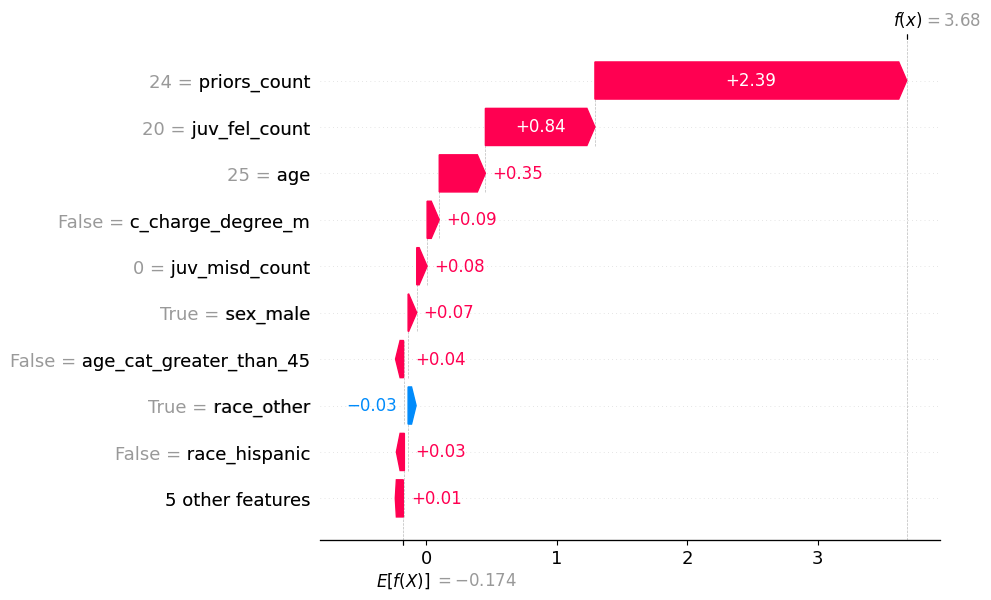

In [11]:
shap_values_test = explainer(X_test)

shap.plots.waterfall(shap_values_test[X_test.index.get_loc(idx_caso1)])

*Tu turno: escribe aquí la narrativa del Caso 1, según SHAP.*

Este caso corresponde a una persona de 25 años, con **24 antecedentes penales previos** y **20 delitos graves cometidos como menor de edad**. El modelo le asigna una probabilidad de reincidencia de **97.5%**, y acertó: la persona sí reincidió dentro de los dos años.

El gráfico de waterfall muestra que el factor que más empuja la predicción hacia "alto riesgo" es, con enorme diferencia, la cantidad de antecedentes penales (`priors_count = 24`), seguido por el historial de delitos graves cometidos como menor de edad (`juv_fel_count = 20`) y, en menor medida, su edad joven (25 años).

**Explicación para un lector no técnico (juez / oficial de libertad condicional):** el modelo no está clasificando a esta persona como "alto riesgo" por quién es o de dónde viene, sino por su historial documentado: un número muy alto de antecedentes penales, incluyendo delitos graves desde que era menor de edad. Es, en esencia, un patrón de reincidencia sostenido a lo largo del tiempo, y eso es lo que domina la decisión del modelo, no una característica demográfica.

### LIME Explanation: Caso 2

Genera una explicación de LIME para el Caso 2 (baja probabilidad de reincidencia), y escribe la narrativa correspondiente.

Probabilidad predicha (no_reincide, reincide): [0.9237932 0.0762068]
priors_count <= 0.00 -0.2674
age > 41.00 -0.1412
race_asian <= 0.00 0.0863
race_native_american <= 0.00 0.0654
juv_fel_count <= 0.00 -0.048
c_charge_degree_m <= 0.00 0.0468
race_other > 0.00 -0.0407
race_hispanic <= 0.00 0.0296


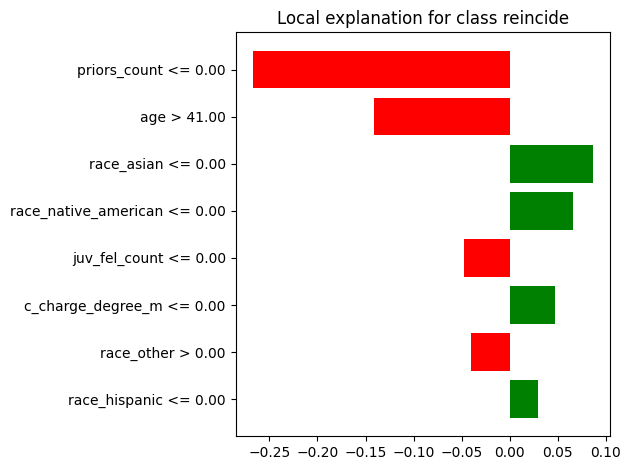

In [12]:
lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=list(X_train.columns),
    class_names=["no_reincide", "reincide"],
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

exp = lime_explainer.explain_instance(
    X_test.loc[idx_caso2].values,
    model.predict_proba,
    num_features=8
)

print("Probabilidad predicha (no_reincide, reincide):", model.predict_proba(X_test.loc[[idx_caso2]])[0])
for feat, weight in exp.as_list():
    print(feat, round(weight, 4))

fig = exp.as_pyplot_figure()
fig.tight_layout()

*Tu turno: escribe aquí la narrativa del Caso 2, según LIME.*

Este caso corresponde a una persona de 64 años, sin antecedentes penales previos (`priors_count = 0`), sin historial de delitos como menor de edad, y sin cargo actual por delito menor. El modelo le asigna una probabilidad de reincidencia de apenas **7.6%**, y acertó: la persona no reincidió.

LIME muestra que los dos factores que más empujan la predicción hacia "no reincide" son, en orden: no tener antecedentes penales (`priors_count <= 0`) y tener más de 41 años. El resto de las variables (relacionadas con raza) tienen un peso mucho menor y no cambian la dirección general de la predicción.

**Explicación para un lector no técnico:** el modelo considera que esta persona tiene bajo riesgo principalmente porque no tiene ningún historial delictivo previo y porque, a mayor edad, la probabilidad de reincidencia observada en los datos disminuye. Es una decisión basada en la ausencia de antecedentes, no en su identidad.

## Fase 4: Evaluación de IA Ética

Esta es la fase más importante del ejercicio. Vamos a investigar si el modelo se apoya en variables sesgadas o inapropiadas, usando las mismas dos estrategias que practicamos en la Sesión 3: revisar el ranking de importancia SHAP, y comparar las tasas reales vs. predichas entre grupos.

### Tu turno: ranking de variables sensibles

Revisa en qué posición del ranking de importancia SHAP quedan las variables relacionadas con `race` y `sex`.

In [13]:
mean_abs_shap = np.abs(shap_values).mean(axis=0)
ranking = pd.DataFrame({
    "variable": X_train.columns,
    "importancia_media_shap": mean_abs_shap
}).sort_values("importancia_media_shap", ascending=False).reset_index(drop=True)

ranking.index = ranking.index + 1
print(ranking)

print("\nPosicion de variables relacionadas con 'race':")
print(ranking[ranking["variable"].str.startswith("race")])

print("\nPosicion de 'sex_male':")
print(ranking[ranking["variable"] == "sex_male"])

                   variable  importancia_media_shap
1              priors_count                0.645990
2                       age                0.407043
3         c_charge_degree_m                0.111212
4                  sex_male                0.101069
5           juv_other_count                0.048135
6             race_hispanic                0.040997
7            race_caucasian                0.034071
8      age_cat_less_than_25                0.029619
9   age_cat_greater_than_45                0.028461
10           juv_misd_count                0.013990
11               race_other                0.010044
12            juv_fel_count                0.008485
13               race_asian                0.004397
14     race_native_american                0.000659

Posicion de variables relacionadas con 'race':
                variable  importancia_media_shap
6          race_hispanic                0.040997
7         race_caucasian                0.034071
11            race_other 

### Tu turno: ¿el modelo trata distinto a distintos grupos?

Compara, para cada raza y para cada sexo, la tasa real de reincidencia (`two_year_recid`) contra la tasa que predice el modelo. Presta atención también al tamaño de cada grupo antes de sacar conclusiones (recuerda la discusión sobre muestras chicas de la Sesión 3).

In [14]:
resultado = df.loc[X_test.index, ["race", "sex"]].copy()
resultado["real"] = y_test.values
resultado["pred"] = y_pred

print("=== Por raza ===")
comparacion_raza = resultado.groupby("race").agg(
    n=("real", "size"),
    tasa_real=("real", "mean"),
    tasa_predicha=("pred", "mean")
).sort_values("n", ascending=False)
print(comparacion_raza)

print("\n=== Por sexo ===")
comparacion_sexo = resultado.groupby("sex").agg(
    n=("real", "size"),
    tasa_real=("real", "mean"),
    tasa_predicha=("pred", "mean")
)
print(comparacion_sexo)

print("\n=== Tasa de falso positivo por raza (predijo reincide, pero NO reincidio) ===")
for raza, grupo in resultado.groupby("race"):
    negativos = grupo[grupo["real"] == 0]
    if len(negativos) > 0:
        fpr = (negativos["pred"] == 1).mean()
        print(f"{raza}: n={len(negativos)}, FPR={round(fpr, 3)}")

=== Por raza ===
                    n  tasa_real  tasa_predicha
race                                           
African-American  641   0.525741       0.549142
Caucasian         427   0.377049       0.241218
Hispanic           94   0.478723       0.276596
Other              65   0.276923       0.230769
Asian               7   0.142857       0.000000
Native American     1   0.000000       0.000000

=== Por sexo ===
           n  tasa_real  tasa_predicha
sex                                   
Female   233   0.364807       0.184549
Male    1002   0.476048       0.452096

=== Tasa de falso positivo por raza (predijo reincide, pero NO reincidio) ===
African-American: n=304, FPR=0.329
Asian: n=6, FPR=0.0
Caucasian: n=266, FPR=0.139
Hispanic: n=49, FPR=0.143
Native American: n=1, FPR=0.0
Other: n=47, FPR=0.149


### Tu turno: reflexión crítica final

Con base en todo lo que investigaste en esta fase, responde con tus propias palabras:

- ¿Existen indicios de que el modelo se apoya en variables sesgadas o inapropiadas, como `race` o `sex`?
- Aunque `race` no esté entre las variables más importantes, ¿alguna otra variable (por ejemplo `priors_count`) podría estar actuando como un "proxy" de raza, es decir, cargando información asociada indirectamente? Esto fue justamente parte de la crítica que hizo ProPublica al sistema COMPAS real.
- ¿El modelo está tomando decisiones basadas en características irrelevantes o discriminatorias, o está reflejando patrones legítimos del problema?
- Si este modelo se usara para decidir si una persona sale en libertad condicional, ¿qué cambios propondrías antes de llevarlo a producción?


*Tu turno: escribe aquí tu reflexión final de IA ética.*

**¿Existen indicios de que el modelo se apoya en variables sesgadas o inapropiadas?**

De forma directa, no: las variables `race_*` ocupan posiciones bajas en el ranking de importancia SHAP (por debajo de `priors_count`, `age`, `c_charge_degree_m` y `sex_male`), y `sex_male` sí aparece con una importancia moderada. Sin embargo, cuando se comparan las tasas reales de reincidencia contra las tasas predichas por grupo racial, aparece un patrón que reproduce casi exactamente el hallazgo original de ProPublica: la tasa de falsos positivos (personas clasificadas como "alto riesgo" que en realidad no reincidieron) es notablemente más alta para el grupo afroamericano (~33%) que para el grupo caucásico (~14%), a pesar de que la tasa real de reincidencia entre ambos grupos no es tan distinta (52.6% vs 37.7%). Es decir, el modelo no usa `race` explícitamente como variable importante, pero sus errores no se distribuyen igual entre grupos raciales.

**¿Podría `priors_count` estar actuando como proxy de raza?**

Sí, hay evidencia de esto en los propios datos: el promedio de antecedentes penales previos es notablemente más alto en el grupo afroamericano (4.24) que en el grupo caucásico (2.29). Como `priors_count` es, por lejos, la variable más influyente del modelo, y está correlacionada con `race` (probablemente reflejando patrones históricos de vigilancia y arresto desiguales, no necesariamente diferencias reales en el comportamiento), el modelo puede terminar penalizando indirectamente a un grupo racial sin necesitar usar la columna `race` de forma explícita. Esto es exactamente lo que ProPublica documentó en el sistema COMPAS real: el sesgo no entra por la puerta principal (una variable sensible con alta importancia), sino por variables aparentemente neutrales que están correlacionadas con esa variable sensible.

**¿El modelo refleja patrones legítimos o está siendo discriminatorio?**

Es probablemente ambas cosas a la vez, y esa es la parte incómoda del problema. `priors_count` y `age` son señales legítimas y explicables desde el punto de vista criminológico: el historial de conducta pasada y la edad sí predicen reincidencia en cualquier población. El problema no es que el modelo use esas variables, sino que los datos de entrada (quién fue arrestado, cuántas veces, por qué cargos) ya vienen contaminados por décadas de aplicación desigual del sistema de justicia penal. Un modelo entrenado sobre esos datos, aunque sea técnicamente correcto y no use `race` directamente, puede perpetuar y automatizar ese sesgo histórico bajo una apariencia de objetividad matemática.

**¿Qué cambios propondría antes de llevarlo a producción?**

- No usar este tipo de modelo para decidir libertad condicional de forma automática; como máximo, como un insumo más entre varios, revisado por una persona.
- Medir y reportar explícitamente métricas de equidad por grupo (tasa de falso positivo, tasa de falso negativo, no solo accuracy global) antes de aprobar el modelo, y fijar un umbral aceptable de disparidad entre grupos.
- Evaluar si `priors_count` debería ajustarse o ponderarse de otra forma para reducir su rol como proxy racial, o complementarlo con variables que capturen mejor el contexto (por ejemplo, tipo de delito, gravedad, tiempo transcurrido desde el último antecedente) en vez de un simple conteo acumulado.
- Hacer auditorías periódicas del modelo en producción, no solo una validación inicial, porque los patrones de sesgo pueden cambiar con el tiempo y con la población que entra al sistema.
- Ser transparente con las personas afectadas: que exista un mecanismo de apelación humana cuando el modelo asigna un puntaje de alto riesgo, especialmente considerando que aquí está en juego la libertad de una persona.